importing all the required libriaries

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import os
import warnings
warnings.filterwarnings('ignore')

loading the data (compiling all in one df) (the training fwas taking too long do chnaged it to just 1)

In [22]:
combined_data = pd.read_csv("NIFTY-50/BAJAJFINSV.csv")

combined_data

,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble
0,2008-05-26,BAJAJFINSV,EQ,2101.05,600.00,619.00,501.00,505.10,509.10,548.85,3145446,1.726368e+14,NaN,908264,0.2888
1,2008-05-27,BAJAJFINSV,EQ,509.10,505.00,610.95,491.10,564.00,554.65,572.15,4349144,2.488370e+14,NaN,677627,0.1558
2,2008-05-28,BAJAJFINSV,EQ,554.65,564.00,665.60,564.00,643.00,640.95,618.37,4588759,2.837530e+14,NaN,774895,0.1689
3,2008-05-29,BAJAJFINSV,EQ,640.95,656.65,703.00,608.00,634.50,632.40,659.60,4522302,2.982921e+14,NaN,1006161,0.2225
4,2008-05-30,BAJAJFINSV,EQ,632.40,642.40,668.00,588.30,647.00,644.00,636.41,3057669,1.945929e+14,NaN,462832,0.1514
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3196,2021-04-26,BAJAJFINSV,EQ,9916.65,9992.00,10125.00,9902.20,10000.85,10001.75,9995.72,419596,4.194163e+14,45113.0,77816,0.1855
3197,2021-04-27,BAJAJFINSV,EQ,10001.75,10000.00,10133.00,9964.70,10133.00,10091.35,10036.76,342847,3.441072e+14,40414.0,77723,0.2267
3198,2021-04-28,BAJAJFINSV,EQ,10091.35,10200.00,10615.95,10151.15,10480.00,10489.30,10445.96,1113881,1.163556e+15,126354.0,133587,0.1199
3199,2021-04-29,BAJAJFINSV,EQ,10489.30,10540.00,11300.00,10520.00,11175.45,11176.55,10980.40,1696498,1.862822e+15,165425.0,195324,0.1151


normalizing the data

In [23]:
closing_prices = combined_data['Close'].values.reshape(-1, 1)

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(closing_prices)

scaled_data

array([[0.03773747],
       [0.04184633],
       [0.04963106],
       ...,
       [0.93800628],
       [1.        ],
       [0.98783128]], shape=(3201, 1))

defining the create time frame function

In [24]:
def create_time_windows(data, sequence_length=60):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i+sequence_length])
        y.append(data[i+sequence_length])
    return np.array(X), np.array(y)

creating the data

In [25]:
sequence_length = 60
X, y = create_time_windows(scaled_data, sequence_length)

train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((2512, 60, 1), (629, 60, 1), (2512, 1), (629, 1))

defining a lstm model building function

In [26]:
def build_lstm_model(learning_rate=0.001):
    model = Sequential([
        LSTM(50, return_sequences=True, input_shape=(sequence_length, 1)),
        Dropout(0.2),
        LSTM(50, return_sequences=True),
        Dropout(0.2),
        LSTM(25),
        Dropout(0.2),
        Dense(1)
    ])
    
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mse')
    return model

createing a model and running ites summary

In [27]:
model_default = build_lstm_model(learning_rate=0.001)
model_default.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_21 (LSTM)                  │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_22 (LSTM)                  │ (None, 60, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_23 (LSTM)                  │ (None, 25)             │         7,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,226 (149.32 KB)

 Trainable params: 38,226 (149.32 KB)

 Non-trainable params: 0 (0.00 B)

making models with diffrerent learning rates

In [34]:
learning_rates = [0.01, 0.001, 0.0001]
predictions_dict = {}

for lr in learning_rates:
    model = build_lstm_model(learning_rate=lr)
    model.fit(X_train, y_train, epochs=2, batch_size=64, validation_split=0.1, verbose=0)
    y_pred_train = model.predict(X_train, verbose=0)
    y_pred_test = model.predict(X_test, verbose=0)
    predictions_dict[f'lr_{lr}'] = {'train': y_pred_train, 'test': y_pred_test}

predictions_dict

{'lr_0.01': {'train': array([[0.04296188],
         [0.04353435],
         [0.04400686],
         ...,
         [0.49881414],
         [0.49318746],
         [0.48869717]], shape=(2512, 1), dtype=float32),
  'test': array([[0.4856478 ],
         [0.48350728],
         [0.48200178],
         [0.48026726],
         [0.47816098],
         [0.47534925],
         [0.47173014],
         [0.4680691 ],
         [0.4647183 ],
         [0.46193302],
         [0.4598041 ],
         [0.45824814],
         [0.45719194],
         [0.456489  ],
         [0.4563683 ],
         [0.45690948],
         [0.45804763],
         [0.45969427],
         [0.4618407 ],
         [0.46394894],
         [0.46581748],
         [0.4673748 ],
         [0.46866065],
         [0.46994922],
         [0.47138253],
         [0.47285715],
         [0.47467744],
         [0.47652242],
         [0.47825092],
         [0.48012114],
         [0.48199782],
         [0.4842388 ],
         [0.48679775],
         [0.48953328],
    

getting the results and caulucation the RMSE

In [35]:
rmse_results = {}

for lr_key in predictions_dict.keys():
    y_train_pred = predictions_dict[lr_key]['train']
    y_test_pred = predictions_dict[lr_key]['test']
    
    rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
    rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
    
    rmse_results[lr_key] = {'train_rmse': rmse_train, 'test_rmse': rmse_test}

rmse_results_df = pd.DataFrame(rmse_results).T
rmse_results_df

,train_rmse,test_rmse
lr_0.01,0.015384,0.074024
lr_0.001,0.021937,0.097314
lr_0.0001,0.046015,0.170558


the best model based on RMSE is the one with lr as 0.01 it has the least RMSE in both testing and training

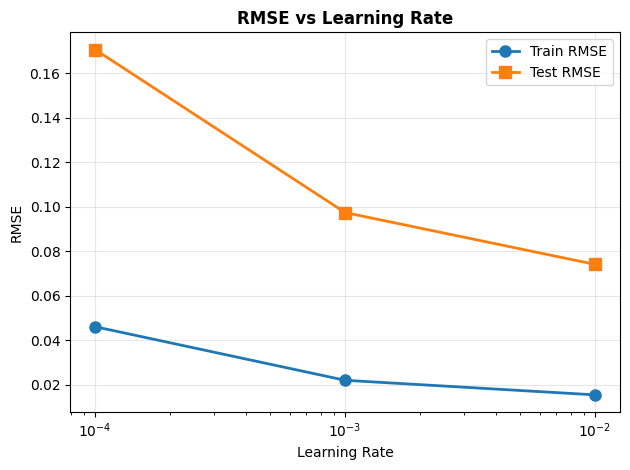

In [36]:
lrs = [lr for lr in learning_rates]
train_rmses = [rmse_results[f'lr_{lr}']['train_rmse'] for lr in lrs]
test_rmses = [rmse_results[f'lr_{lr}']['test_rmse'] for lr in lrs]

plt.plot(lrs, train_rmses, marker='o', label='Train RMSE', linewidth=2, markersize=8)
plt.plot(lrs, test_rmses, marker='s', label='Test RMSE', linewidth=2, markersize=8)
plt.xscale('log')
plt.xlabel('Learning Rate')
plt.ylabel('RMSE')
plt.title('RMSE vs Learning Rate', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

from this we can see the more the learing rate the less the RMSE